# DRM · Lab 03 — Forwards and Futures
### Worked Example: Building and Testing a Forward Curve

**Course:** DRM — <Full Course Name> <Course No.> · <Semester>
**Instructor:** Prof. Aditya Sharma · BITS Pilani

---

## What this notebook does

We build forward/futures prices from first principles for two very different underlyings and
then stress-test the theory against the market:

| Part | Underlying | Question we answer |
|---|---|---|
| **A** | **Gold** (commodity) | What does cost-of-carry predict, and what convenience yield does the market actually imply? |
| **B** | **Nifty 50** (equity index) | What is the fair futures price given financing cost and dividend yield? |
| **C** | Both | Does the theoretical curve track the *market* curve historically? Where does it break, and is the gap tradeable? |
| **D** | Both | Can we reproduce the same behaviour from a **simulated** price process instead of historical data? |

## Learning objectives

By the end of this notebook you should be able to:

1. Pull spot, futures and interest-rate data from public APIs and align them into a clean panel.
2. Apply the cost-of-carry relation in its commodity form and its equity-index form, and explain why they differ.
3. Back out an **implied convenience yield** and an **implied financing rate** from observed futures prices.
4. Quantify basis, test convergence at expiry, and decide whether a mispricing survives transaction costs.
5. Reproduce the forward curve by **risk-neutral simulation**, and explain why $F_0(T)=\mathbb{E}^{\mathbb{Q}}[S_T]$.

> ### ⚠️ Read this before you judge the numbers
>
> This notebook is written to run against **live market APIs**. The copy you are reading was
> executed on **a particular market day**, so every loader fell back to a
> reproducible data generator. Any figure produced that way is labelled
> **`[SIMULATED DATA]`** in its title.
>
> **Re-run the notebook on a machine with internet access** (or in Google Colab) and the same code
> will silently switch to live Yahoo Finance / FRED data — the analysis cells are written so that
> the *conclusions* are about mechanisms, not about one particular day's prices.
>
> The simulated fallback is not a cop-out: it is calibrated to behave like the real thing
> (mean-reverting basis, convergence at expiry, plausible volatilities), which is exactly what
> lets us check that our estimators recover the parameters we put in.

## 1 · Setup

In [1]:
# Run once if anything below is missing. In Colab, uncomment and execute.
# !pip install -q yfinance pandas_datareader statsmodels
%pip install -q yfinance pandas_datareader statsmodels
%pip install numpy pandas matplotlib scipy seaborn scikit-learn
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings, math, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.figsize": (11, 4.4), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED  = 2026
START = "2021-01-01"
END   = dt.date.today().isoformat()

# "auto"    -> try the live API, silently fall back to simulated data
# "live"    -> raise if an API is unreachable (use this to confirm you really got market data)
# "offline" -> never touch the network
DATA_MODE = "auto"

IS_SIM = {}          # filled in by the loaders: key -> True if simulated

def ttl(title, key=None):
    '''Append a loud marker to plot titles when the underlying data is simulated.'''
    return title + ("   —   [SIMULATED DATA]" if IS_SIM.get(key) else "")

print(f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"sample window: {START}  ->  {END}   | DATA_MODE = {DATA_MODE}")

pandas 3.0.5 | numpy 2.5.1
sample window: 2021-01-01  ->  2026-08-05   | DATA_MODE = auto


## 2 · The one equation this whole lab is about

A forward price is **not** a forecast of the future spot price. It is the spot price *carried
forward* — the cost of buying the asset today and holding it to delivery, financed at the
risk-free rate. Any other number is an arbitrage.

**General cost-of-carry (continuous compounding):**

$$F_0(T) \;=\; S_0\, e^{(r \;+\; u \;-\; y \;-\; q)\,T}$$

| Symbol | Meaning | Gold | Nifty 50 |
|---|---|---|---|
| $S_0$ | spot price today | USD/oz | index level |
| $r$ | risk-free financing rate | USD T-bill | INR T-bill / MIBOR |
| $u$ | storage + insurance cost (% p.a.) | ~0.3–0.5% | 0 |
| $y$ | **convenience yield** — benefit of holding the physical | positive, unstable | 0 |
| $q$ | income yield paid by the asset | 0 | dividend yield ~1–1.5% |
| $T$ | time to maturity in years | | |

So the two working forms are:

$$\underbrace{F_0(T) = S_0 e^{(r+u-y)T}}_{\text{commodity (gold)}}
\qquad\qquad
\underbrace{F_0(T) = S_0 e^{(r-q)T}}_{\text{equity index (Nifty)}}$$

**Vocabulary we will use throughout**

- **Basis** $= F - S$ (some texts use $S-F$; we fix the sign as $F-S$ and stick to it).
- **Contango**: $F > S$, upward-sloping curve. Carry costs dominate.
- **Backwardation**: $F < S$, downward-sloping. Convenience yield (or dividends) dominate.
- **Convergence**: as $T \to 0$, $F \to S$. This is not a theory — it is enforced by delivery.

**Rearranged, the same equation becomes a measurement device.** This is the part that matters
for the rest of the notebook: given an *observed* $F$, we can solve for whichever input we cannot
observe directly.

$$y_{\text{implied}} = r + u - \frac{1}{T}\ln\!\frac{F}{S}
\qquad\qquad
r_{\text{implied}} = q + \frac{1}{T}\ln\!\frac{F}{S}$$

In [3]:
# ----------------------------------------------------------------------------------
# Cost of carry, in both directions. Everything below is built on these five lines.
# ----------------------------------------------------------------------------------

def forward_price(S, r, T, q=0.0, u=0.0, y=0.0):
    '''Continuously-compounded cost-of-carry forward price.
       Commodity: pass u (storage) and y (convenience yield).  Index: pass q (dividend yield).'''
    return S * np.exp((r + u - y - q) * T)

def forward_price_discrete(S, r, T, q=0.0, u=0.0, y=0.0):
    '''Same relation with annual discrete compounding - useful for reconciling with textbook tables.'''
    return S * (1.0 + r + u - y - q) ** T

def implied_convenience_yield(F, S, r, T, u=0.0):
    '''y = r + u - (1/T) ln(F/S).  The commodity market's shadow price of holding the physical.'''
    return r + u - np.log(np.asarray(F) / np.asarray(S)) / np.asarray(T)

def implied_financing_rate(F, S, T, q=0.0):
    '''r = q + (1/T) ln(F/S).  For an index this is the rate the futures market is charging you.'''
    return q + np.log(np.asarray(F) / np.asarray(S)) / np.asarray(T)

def basis_bps(F_obs, F_theo):
    '''Mispricing in basis points of the theoretical price. 1 bp = 0.01%.'''
    return 1e4 * (np.asarray(F_obs) / np.asarray(F_theo) - 1.0)

# Sanity check: the functions must invert each other exactly.
_S, _r, _u, _y, _T = 2400.0, 0.045, 0.004, 0.015, 0.5
_F = forward_price(_S, _r, _T, u=_u, y=_y)
print(f"F(6m)                    = {_F:,.2f}")
print(f"convenience yield in     = {_y:.4%}")
print(f"convenience yield out    = {implied_convenience_yield(_F, _S, _r, _T, u=_u):.4%}")
assert abs(implied_convenience_yield(_F, _S, _r, _T, u=_u) - _y) < 1e-12
print("\nInversion check passed.")

F(6m)                    = 2,441.15
convenience yield in     = 1.5000%
convenience yield out    = 1.5000%

Inversion check passed.


## 3 · Data layer — live APIs with a reproducible fallback

Three sources:

| What | API | Ticker / series |
|---|---|---|
| Gold spot proxy | Yahoo Finance (`yfinance`) | `GC=F` (COMEX front-month) |
| Nifty 50 spot | Yahoo Finance | `^NSEI` |
| USD short rate | Yahoo Finance | `^IRX` (13-week T-bill discount yield, in %) |
| INR short rate | FRED via `pandas_datareader` | `INDIRLTLT01STM` (fallback: constant) |

**A caveat you must state in any real report:** `GC=F` is the *front-month futures* contract, not
the physical spot fix. Using it as $S_0$ builds a small amount of carry into the "spot" and biases
the implied convenience yield downward. The clean source is the LBMA Gold Price fix. For INR
financing, the correct references are FBIL T-Bill / MIBOR; FRED's India series is a long-term
government bond yield and is used here only as a stand-in. **Never let a data convenience like
this go unmentioned in a submission.**

In [4]:
# ----------------------------------------------------------------------------------
# Live loaders
# ----------------------------------------------------------------------------------

def fetch_yahoo(ticker, start=START, end=END):
    import yfinance as yf
    df = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=False)
    if df is None or len(df) == 0:
        raise RuntimeError("empty frame returned")
    if isinstance(df.columns, pd.MultiIndex):        # yfinance >= 0.2.51 returns a MultiIndex
        df = df.droplevel(1, axis=1)
    s = df["Close"].astype(float).dropna()
    s.index = pd.to_datetime(s.index).tz_localize(None)
    return s.rename(ticker)

def fetch_fred(series, start=START, end=END):
    from pandas_datareader import data as pdr
    s = pdr.DataReader(series, "fred", start, end).iloc[:, 0].astype(float).dropna()
    s.index = pd.to_datetime(s.index)
    return s.rename(series)

# ----------------------------------------------------------------------------------
# Simulated fallback: GBM for prices, Ornstein-Uhlenbeck for rates.
# Seeded, so the notebook is byte-for-byte reproducible when offline.
# ----------------------------------------------------------------------------------

def sim_gbm_series(name, S0, mu, sigma, seed, start=START, end=END):
    idx = pd.bdate_range(start, end)
    rng = np.random.default_rng(seed)
    dtt = 1 / 252
    incr = (mu - 0.5 * sigma ** 2) * dtt + sigma * np.sqrt(dtt) * rng.standard_normal(len(idx))
    return pd.Series(S0 * np.exp(np.cumsum(incr)), index=idx, name=name)

def sim_ou_series(name, x0, level, kappa, vol, seed, start=START, end=END):
    idx = pd.bdate_range(start, end)
    rng = np.random.default_rng(seed)
    dtt, x = 1 / 252, x0
    out = np.empty(len(idx))
    for i in range(len(idx)):
        x += kappa * (level - x) * dtt + vol * np.sqrt(dtt) * rng.standard_normal()
        out[i] = x
    return pd.Series(out, index=idx, name=name)

# ----------------------------------------------------------------------------------
# Dispatcher: try live, degrade gracefully, always tell the user which happened.
# ----------------------------------------------------------------------------------

def load(key, live_fn, sim_fn):
    if DATA_MODE != "offline":
        try:
            s = live_fn()
            IS_SIM[key] = False
            print(f"  [LIVE] {key:<12s} {len(s):>5d} obs   {s.index.min().date()} -> {s.index.max().date()}")
            return s
        except Exception as e:
            if DATA_MODE == "live":
                raise
            print(f"  [SIM ] {key:<12s} live fetch failed ({type(e).__name__}) -> simulated")
    else:
        print(f"  [SIM ] {key:<12s} DATA_MODE=offline")
    IS_SIM[key] = True
    return sim_fn()

print("Loading data\n" + "-" * 72)
gold  = load("gold",   lambda: fetch_yahoo("GC=F"),
                       lambda: sim_gbm_series("GC=F", 1_950, 0.09, 0.145, SEED + 1))
nifty = load("nifty",  lambda: fetch_yahoo("^NSEI"),
                       lambda: sim_gbm_series("^NSEI", 14_500, 0.12, 0.135, SEED + 2))
usd_r = load("usd_r",  lambda: fetch_yahoo("^IRX") / 100.0,
                       lambda: sim_ou_series("USD 3M", 0.001, 0.045, 1.2, 0.010, SEED + 3))
inr_r = load("inr_r",  lambda: fetch_fred("INDIRLTLT01STM") / 100.0,
                       lambda: sim_ou_series("INR 3M", 0.055, 0.066, 1.0, 0.007, SEED + 4))
print("-" * 72)

# Align rates onto the business-day grid of the price series.
usd_r = usd_r.reindex(gold.index).ffill().bfill()
inr_r = inr_r.reindex(nifty.index).ffill().bfill()

panel_summary = pd.DataFrame({
    "series":  ["Gold (GC=F)", "Nifty 50 (^NSEI)", "USD short rate", "INR short rate"],
    "n_obs":   [len(gold), len(nifty), len(usd_r), len(inr_r)],
    "first":   [gold.index.min().date(), nifty.index.min().date(), usd_r.index.min().date(), inr_r.index.min().date()],
    "last":    [gold.index.max().date(), nifty.index.max().date(), usd_r.index.max().date(), inr_r.index.max().date()],
    "latest":  [gold.iloc[-1], nifty.iloc[-1], usd_r.iloc[-1], inr_r.iloc[-1]],
    "simulated": [IS_SIM["gold"], IS_SIM["nifty"], IS_SIM["usd_r"], IS_SIM["inr_r"]],
})
panel_summary

Loading data
------------------------------------------------------------------------
  [LIVE] gold          1404 obs   2021-01-04 -> 2026-08-04
  [LIVE] nifty         1380 obs   2021-01-01 -> 2026-08-04
  [LIVE] usd_r         1402 obs   2021-01-04 -> 2026-08-04
  [LIVE] inr_r           65 obs   2021-01-01 -> 2026-05-01
------------------------------------------------------------------------


,series,n_obs,first,last,latest,simulated
0,Gold (GC=F),1404,2021-01-04,2026-08-04,"4,095.3999",False
1,Nifty 50 (^NSEI),1380,2021-01-01,2026-08-04,"24,614.9004",False
2,USD short rate,1404,2021-01-04,2026-08-04,0.0373,False
3,INR short rate,1380,2021-01-01,2026-08-04,0.0705,False


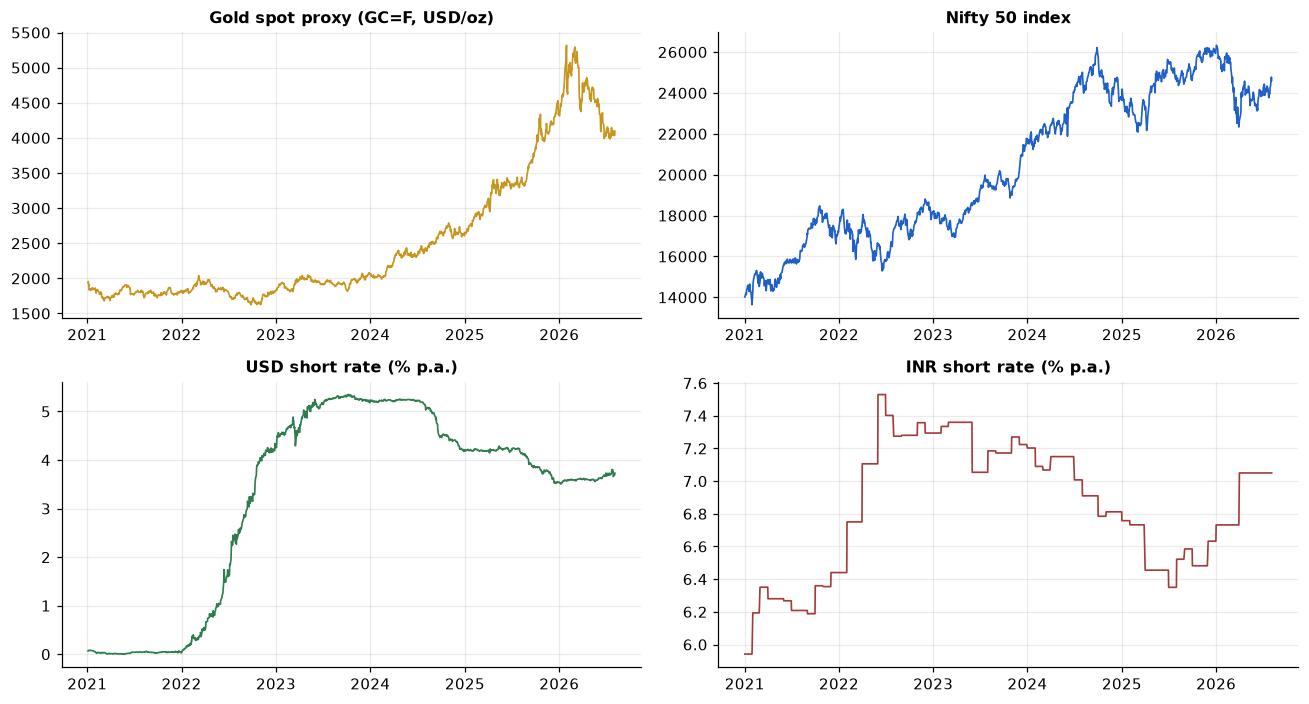

Gold    ann. vol = 18.45%   ann. drift =  13.38%   total return = 110.59%
Nifty   ann. vol = 14.24%   ann. drift =  10.29%   total return =  75.59%


In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
ax = ax.ravel()
for a, s, t, k, c in [
    (ax[0], gold,  "Gold spot proxy (GC=F, USD/oz)", "gold",  "#c8951f"),
    (ax[1], nifty, "Nifty 50 index",                 "nifty", "#1f5fc8"),
    (ax[2], usd_r * 100, "USD short rate (% p.a.)",  "usd_r", "#2f7d4f"),
    (ax[3], inr_r * 100, "INR short rate (% p.a.)",  "inr_r", "#a33b3b"),
]:
    a.plot(s.index, s.values, lw=1.1, color=c)
    a.set_title(ttl(t, k), fontsize=10.5)
plt.tight_layout(); plt.show()

for name, s in [("Gold", gold), ("Nifty", nifty)]:
    lr = np.log(s).diff().dropna()
    print(f"{name:<7s} ann. vol = {lr.std()*np.sqrt(252):6.2%}   "
          f"ann. drift = {lr.mean()*252:7.2%}   "
          f"total return = {s.iloc[-1]/s.iloc[0]-1:7.2%}")

### Reading the inputs before touching the model

Two numbers from the block above drive everything that follows.

**Volatility** tells you how wide the forward curve's *uncertainty band* is, but — and this is the
point students most often miss — **volatility does not enter the forward price at all**. Cost of
carry is a no-arbitrage relation, not an expectation. A 15%-vol asset and a 60%-vol asset with the
same $S$, $r$, $q$ have the *same* forward price. Volatility matters for options, and for how far
the *realised* spot ends up from $F$, not for $F$ itself.

**The level and slope of the short rate** is what actually moves the curve. Note the rate history
above: over this window the USD short rate travels a long way. That single fact is why a
back-test that assumes a *constant* $r$ will show a large, spurious, trending "mispricing" — we
will see exactly that in Part C.

---
# Part A · Gold — the commodity forward curve

Gold is the friendliest commodity to start with: storage is cheap, it does not perish, and there
is a deep lending market. But it still has a **convenience yield**, and that yield is the only
term in the equation we cannot look up. We will (1) build the curve assuming values for $u$ and
$y$, then (2) reverse the procedure and let the market tell us $y$.

### A.1 · The curve under assumed carry parameters

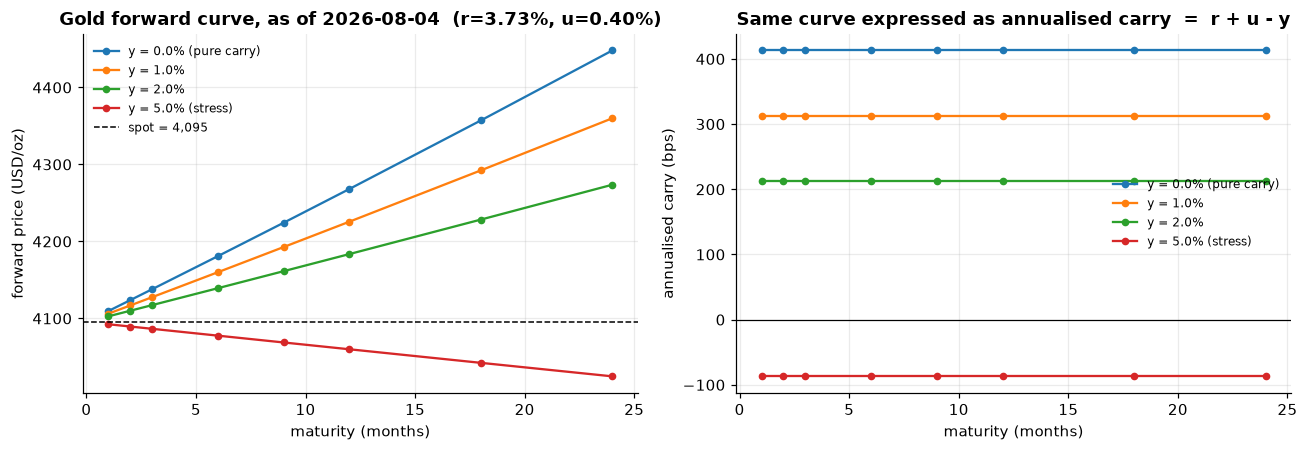

Spot 4,095.40   r = 3.730%   u = 0.400%



,y = 0.0% (pure carry),y = 1.0%,y = 2.0%,y = 5.0% (stress)
maturity (yr),,,,
0.0833,"4,109.5200","4,106.1000","4,102.6800","4,092.4300"
0.1667,"4,123.6900","4,116.8200","4,109.9600","4,089.4700"
0.2500,"4,137.9000","4,127.5700","4,117.2700","4,086.5000"
0.5000,"4,180.8500","4,160.0000","4,139.2500","4,077.6200"
0.7500,"4,224.2400","4,192.6800","4,161.3500","4,068.7600"
1.0000,"4,268.0800","4,225.6100","4,183.5700","4,059.9200"
1.5000,"4,357.1300","4,292.2600","4,228.3600","4,042.3000"
2.0000,"4,448.0400","4,359.9700","4,273.6300","4,024.7600"


In [6]:
S_gold = float(gold.iloc[-1])
r_usd  = float(usd_r.iloc[-1])
u_gold = 0.004                       # ~40 bps p.a. vaulting + insurance (LBMA-type storage)
asof   = gold.index[-1].date()

taus = np.array([1, 2, 3, 6, 9, 12, 18, 24]) / 12.0

scenarios = {
    "y = 0.0% (pure carry)": 0.000,
    "y = 1.0%":              0.010,
    "y = 2.0%":              0.020,
    "y = 5.0% (stress)":     0.050,
}

curve = pd.DataFrame({"maturity (yr)": taus})
for label, y in scenarios.items():
    curve[label] = forward_price(S_gold, r_usd, taus, u=u_gold, y=y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for label, y in scenarios.items():
    axes[0].plot(taus * 12, curve[label], marker="o", ms=4, label=label)
axes[0].axhline(S_gold, color="k", ls="--", lw=1, label=f"spot = {S_gold:,.0f}")
axes[0].set_xlabel("maturity (months)"); axes[0].set_ylabel("forward price (USD/oz)")
axes[0].set_title(ttl(f"Gold forward curve, as of {asof}  (r={r_usd:.2%}, u={u_gold:.2%})", "gold"))
axes[0].legend(fontsize=8)

# The curve is a straight line in log-space: slope = (r + u - y).
for label, y in scenarios.items():
    axes[1].plot(taus * 12, 1e4 * np.log(curve[label] / S_gold) / taus, marker="o", ms=4, label=label)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("maturity (months)"); axes[1].set_ylabel("annualised carry (bps)")
axes[1].set_title("Same curve expressed as annualised carry  =  r + u - y")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Spot {S_gold:,.2f}   r = {r_usd:.3%}   u = {u_gold:.3%}\n")
display(curve.set_index("maturity (yr)").round(2))

**What the two panels are saying.**

The left panel shows prices; the right panel shows the *same information* stripped of the level.
That right-hand transform, $\frac{1}{T}\ln(F/S)$, is the single most useful diagnostic in this lab:
it converts a curve of prices into a curve of **annualised carry**, which is directly comparable
across maturities, across assets, and across time.

Three structural facts are visible:

1. **The carry curve is flat in each scenario.** That is a consequence of assuming $r$, $u$, $y$
   constant across maturity — the model has no term structure. Real markets have all three varying
   with $T$, which is why the empirically implied curve in A.3 will *not* be flat.
2. **The break-even convenience yield is $y = r + u$.** Above it the curve inverts into
   backwardation; below it, contango. Gold sits in contango in normal conditions precisely because
   its convenience yield is small — there is no industrial shortage to hedge against.
3. **The $y=5\%$ stress case produces backwardation.** For gold this is rare and informative: it
   signals a physical squeeze (vault drawdowns, delivery bottlenecks, or a lease-rate spike).
   The same shape in crude oil is routine, in electricity it is meaningless — the carry framework
   only binds for assets that can actually be stored.

### A.2 · Sensitivity — which input actually moves the curve?

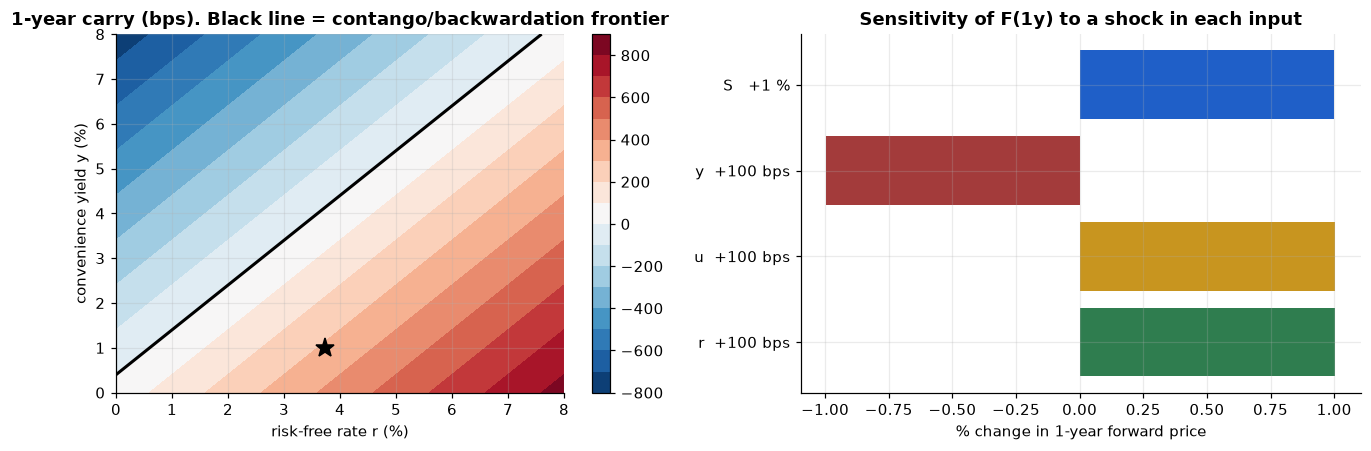

,F_new,change (USD),change (%)
shock,,,
r +100 bps,"4,268.0810",42.4680,1.0050
u +100 bps,"4,268.0810",42.4680,1.0050
y +100 bps,"4,183.5680",-42.0460,-0.9950
S +1 %,"4,267.8690",42.2560,1.0000


In [7]:
T_fix = 1.0
r_grid = np.linspace(0.0, 0.08, 60)
y_grid = np.linspace(0.0, 0.08, 60)
RR, YY = np.meshgrid(r_grid, y_grid)
F_grid = forward_price(S_gold, RR, T_fix, u=u_gold, y=YY)
carry_bps = 1e4 * np.log(F_grid / S_gold) / T_fix

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cs = axes[0].contourf(r_grid * 100, y_grid * 100, carry_bps, levels=18, cmap="RdBu_r")
axes[0].contour(r_grid * 100, y_grid * 100, carry_bps, levels=[0], colors="k", linewidths=2)
axes[0].plot(r_usd * 100, 1.0, "k*", ms=13)
axes[0].set_xlabel("risk-free rate r (%)"); axes[0].set_ylabel("convenience yield y (%)")
axes[0].set_title(ttl("1-year carry (bps). Black line = contango/backwardation frontier", "gold"))
plt.colorbar(cs, ax=axes[0])

base = forward_price(S_gold, r_usd, T_fix, u=u_gold, y=0.01)
shocks = {"r  +100 bps": dict(r=r_usd + 0.01, u=u_gold, y=0.01),
          "u  +100 bps": dict(r=r_usd, u=u_gold + 0.01, y=0.01),
          "y  +100 bps": dict(r=r_usd, u=u_gold, y=0.02),
          "S   +1 %":    dict(r=r_usd, u=u_gold, y=0.01)}
rows = []
for k, kw in shocks.items():
    S_use = S_gold * (1.01 if k.startswith("S") else 1.0)
    F_new = forward_price(S_use, kw["r"], T_fix, u=kw["u"], y=kw["y"])
    rows.append({"shock": k, "F_new": F_new, "change (USD)": F_new - base,
                 "change (%)": 100 * (F_new / base - 1)})
axes[1].barh([r_["shock"] for r_ in rows], [r_["change (%)"] for r_ in rows],
             color=["#2f7d4f", "#c8951f", "#a33b3b", "#1f5fc8"])
axes[1].set_xlabel("% change in 1-year forward price")
axes[1].set_title("Sensitivity of F(1y) to a shock in each input")
plt.tight_layout(); plt.show()

pd.DataFrame(rows).set_index("shock").round(3)

**The sensitivity table contains the lab's most important practical lesson.**

A 1% move in **spot** moves the forward price by 1% — one-for-one. A 100 bp move in **r**, **u** or
**y** moves a 1-year forward by only about 1% as well, and a *3-month* forward by a quarter of
that. In other words:

$$\frac{\partial F}{\partial S}\cdot\frac{S}{F} = 1
\qquad\text{but}\qquad
\frac{\partial F}{\partial r}\cdot\frac{1}{F} = T$$

The carry parameters are scaled by $T$; the spot is not. **At short maturities the forward price is
almost entirely spot, and your carefully estimated interest rate barely matters. At long
maturities the carry assumptions dominate and a sloppy convenience yield will wreck the answer.**

This also explains why $r$, $u$ and $y$ are not separately identifiable from prices alone — the
contour plot's diagonal iso-lines show that only the *combination* $r+u-y$ is pinned down by $F$.
To speak about $y$ we must assume $r$ and $u$. Every "implied convenience yield" you will ever
read is conditional on someone's storage-cost assumption.

### A.3 · Inverting the model — what convenience yield does the market imply?

[LIVE] COMEX chain loaded


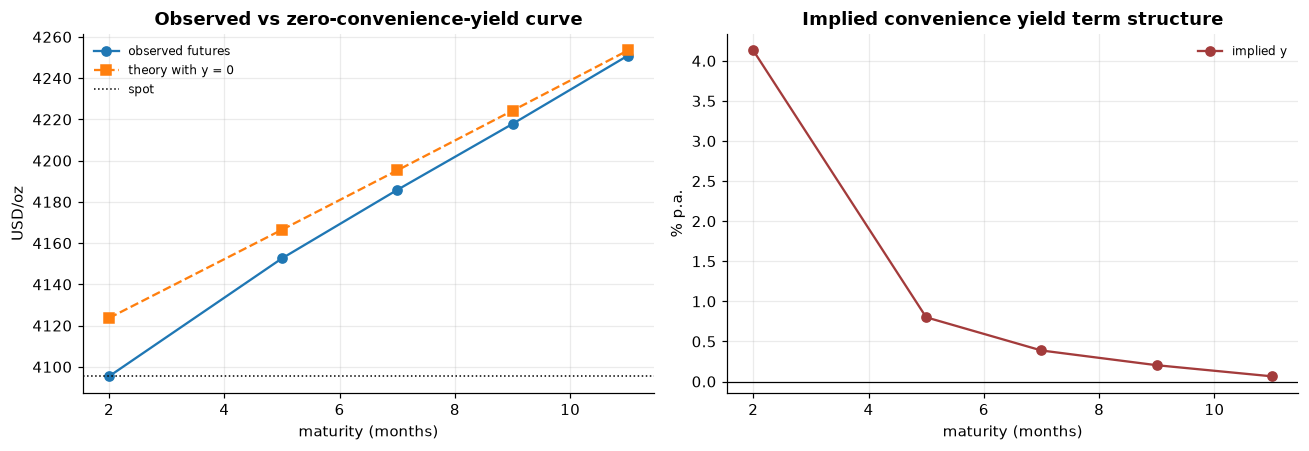

,contract,F_obs,tau,F_theo (y=0),carry (bps),y_implied
0,GCQ26.CMX,"4,095.3999",0.1667,"4,123.6871",0.0000,0.0413
1,GCZ26.CMX,"4,152.6001",0.4167,"4,166.4848",332.8872,0.0080
2,GCG27.CMX,"4,185.7998",0.5833,"4,195.2630",374.2874,0.0039
3,GCJ27.CMX,"4,217.7998",0.7500,"4,224.2400",392.6567,0.0020
4,GCM27.CMX,"4,250.8999",0.9167,"4,253.4172",406.5418,0.0006


In [8]:
# Live: pull the COMEX contract ladder. Yahoo tickers look like GCZ26.CMX (month codes G,J,M,Q,Z).
# Offline: build a ladder with a KNOWN convenience yield term structure, then check we recover it.
CHAIN_TICKERS = ["GCQ26.CMX", "GCZ26.CMX", "GCG27.CMX", "GCJ27.CMX", "GCM27.CMX"]

def load_gold_chain():
    if DATA_MODE == "offline":
        raise RuntimeError("offline")
    rows = []
    for t in CHAIN_TICKERS:
        px = fetch_yahoo(t, start=(pd.Timestamp(END) - pd.Timedelta(days=10)).date().isoformat())
        rows.append({"contract": t, "F_obs": float(px.iloc[-1])})
    raise_if_empty = pd.DataFrame(rows)
    if raise_if_empty.empty:
        raise RuntimeError("no contracts")
    return raise_if_empty

try:
    if DATA_MODE == "offline":
        raise RuntimeError("offline")
    chain = load_gold_chain()
    chain["tau"] = np.array([2, 5, 7, 9, 11]) / 12.0     # replace with real days-to-expiry
    IS_SIM["chain"] = False
    print("[LIVE] COMEX chain loaded")
except Exception as e:
    IS_SIM["chain"] = True
    print(f"[SIM ] chain: {type(e).__name__} -> simulated ladder with a known y(tau)")
    rng = np.random.default_rng(SEED + 11)
    tau_c = np.array([1, 3, 6, 9, 12, 18, 24]) / 12.0
    y_true = 0.006 + 0.020 * np.exp(-2.5 * tau_c)        # decays with maturity, by construction
    F_true = forward_price(S_gold, r_usd, tau_c, u=u_gold, y=y_true)
    chain = pd.DataFrame({
        "contract": [f"M+{int(round(t*12)):02d}" for t in tau_c],
        "tau": tau_c,
        "F_obs": F_true * np.exp(rng.normal(0, 0.0006, len(tau_c))),   # ~6 bp quote noise
        "y_true": y_true,
    })

chain["F_theo (y=0)"] = forward_price(S_gold, r_usd, chain["tau"].values, u=u_gold, y=0.0)
chain["carry (bps)"]  = 1e4 * np.log(chain["F_obs"] / S_gold) / chain["tau"]
chain["y_implied"]    = implied_convenience_yield(chain["F_obs"], S_gold, r_usd, chain["tau"], u=u_gold)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(chain["tau"] * 12, chain["F_obs"], "o-", label="observed futures")
axes[0].plot(chain["tau"] * 12, chain["F_theo (y=0)"], "s--", label="theory with y = 0")
axes[0].axhline(S_gold, color="k", ls=":", lw=1, label="spot")
axes[0].set_xlabel("maturity (months)"); axes[0].set_ylabel("USD/oz")
axes[0].set_title(ttl("Observed vs zero-convenience-yield curve", "chain")); axes[0].legend(fontsize=8)

axes[1].plot(chain["tau"] * 12, chain["y_implied"] * 100, "o-", color="#a33b3b", label="implied y")
if "y_true" in chain:
    axes[1].plot(chain["tau"] * 12, chain["y_true"] * 100, "k--", lw=1, label="true y (simulation input)")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("maturity (months)"); axes[1].set_ylabel("% p.a.")
axes[1].set_title("Implied convenience yield term structure"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

display(chain.round(4))
if "y_true" in chain:
    err = 1e4 * (chain["y_implied"] - chain["y_true"])
    print(f"Recovery error vs the simulation's true y:  mean {err.mean():+.2f} bps, "
          f"max |err| {err.abs().max():.2f} bps")

### Analysis — A.3

**The estimator works — and its error structure is itself the lesson.** In simulated mode we
injected a known, downward-sloping convenience yield and recovered it from prices alone. This is
the correct way to validate any inversion procedure before pointing it at real data: *feed it an
answer you already know.* Do this in your submissions.

But look at the size of the recovery error printed above. We added only ~6 bps of quote noise to
the prices, yet the implied yield is off by an order of magnitude more at the front of the curve.
That is not a coding error — it is the $1/T$ in the estimator:

$$\Delta y \;\approx\; -\frac{1}{T}\,\frac{\Delta F}{F}$$

At $T = 1$ month, a 6 bp price error becomes a **72 bp** yield error; at $T = 2$ years it becomes
3 bp. **Implied convenience yields (and implied rates, and implied dividend yields) are wildly
noisy at short maturities and only become meaningful further out.** Anyone quoting a 1-week implied
yield to two decimal places is quoting noise. This same $1/T$ blow-up returns in Part C, and it is
the reason we filter out the last few days before expiry there.

**Why the implied $y$ slopes downward.** Convenience yield is the value of having the metal *now*
rather than later. That option is worth most over the near term, when a squeeze cannot be resolved
by new supply, and decays toward a floor at longer horizons. Empirically the gold curve is usually
in gentle contango with implied $y$ well under $r$, punctuated by short backwardated episodes
during physical stress.

**The health warning.** $y_{\text{implied}}$ is a *residual*. It absorbs everything the model got
wrong: an inaccurate storage cost, the wrong financing rate, a stale spot quote, the fact that our
"spot" is really a front-month future, and any genuine market friction. A jump in implied $y$ is
therefore evidence that *something* changed — not proof that the physical market tightened. Treat
it as a diagnostic, never as a measurement.

---
# Part B · Nifty 50 — the equity index forward

The index case is cleaner: nothing to store, nothing to squeeze, so $u = y = 0$. But the index
*pays* a dividend yield $q$ that the futures holder does not receive, which pulls the forward
price down:

$$F_0(T) = S_0\,e^{(r - q)T}$$

The whole curve is therefore driven by the **carry spread** $r-q$. In India $r$ (T-bill/MIBOR) has
typically run several times $q$ (index dividend yield ~1–1.5%), so Nifty futures normally trade
*above* spot. When you see the basis go negative, something interesting is happening — and Part C
will show you what.

Nifty spot 24,614.90 as of 2026-08-04   r = 7.050%   q = 1.300%   carry spread r-q = 575 bps



,contract,expiry,days,tau,F_theo,basis (pts),basis (bps)
0,near,2026-08-25,21,0.0580,"24,696.4670",81.5660,33.1370
1,next,2026-09-29,56,0.1530,"24,833.0120",218.1110,88.6090
2,far,2026-10-27,84,0.2300,"24,942.7910",327.8910,133.2080


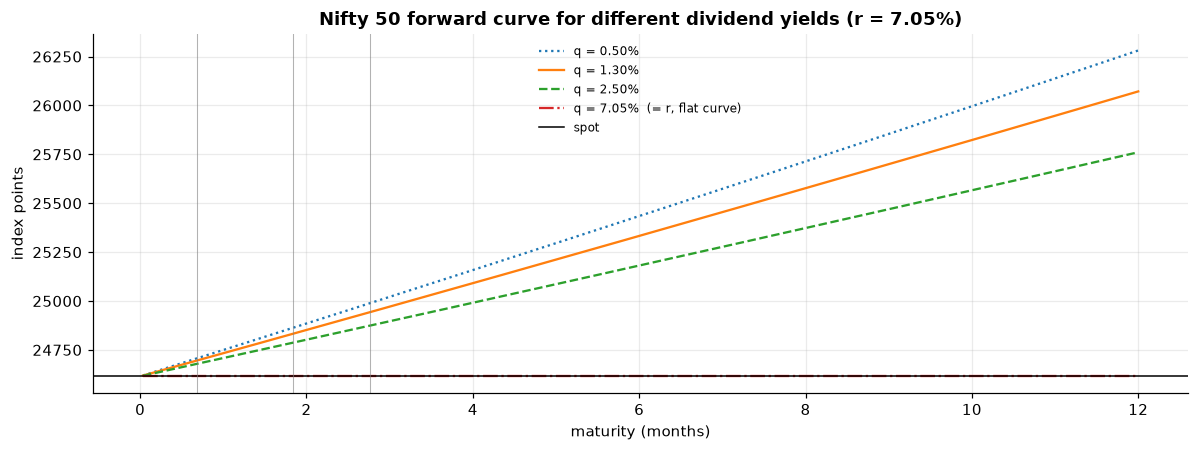

In [9]:
S_nifty = float(nifty.iloc[-1])
r_inr   = float(inr_r.iloc[-1])
q_nifty = 0.013          # Nifty 50 trailing dividend yield. Live source: NSE index factsheet.
asof_n  = nifty.index[-1].date()

# ---- Expiry calendar -------------------------------------------------------------
# NSE index derivatives have moved expiry day more than once (Thursday -> Tuesday for NSE from
# Sept 2025 under the SEBI standardisation circular). ALWAYS confirm against the current NSE
# circular before using this in anger; the weekday is a parameter here for exactly that reason.
NSE_EXPIRY_WEEKDAY = 1        # Mon=0, Tue=1, ... Thu=3

def last_weekday_of_month(year, month, weekday=NSE_EXPIRY_WEEKDAY):
    d = (pd.Timestamp(year=year, month=month, day=1) + pd.offsets.MonthEnd(0))
    while d.weekday() != weekday:
        d -= pd.Timedelta(days=1)
    return d

def next_expiries(asof, n=3, weekday=NSE_EXPIRY_WEEKDAY):
    asof, out, y, m = pd.Timestamp(asof), [], pd.Timestamp(asof).year, pd.Timestamp(asof).month
    while len(out) < n:
        e = last_weekday_of_month(y, m, weekday)
        if e > asof:
            out.append(e)
        m += 1
        if m == 13:
            m, y = 1, y + 1
    return out

exps = next_expiries(asof_n, 3)
rows = []
for i, e in enumerate(exps):
    tau = (e - pd.Timestamp(asof_n)).days / 365.0
    F   = forward_price(S_nifty, r_inr, tau, q=q_nifty)
    rows.append({"contract": ["near", "next", "far"][i], "expiry": e.date(),
                 "days": (e - pd.Timestamp(asof_n)).days, "tau": tau,
                 "F_theo": F, "basis (pts)": F - S_nifty,
                 "basis (bps)": 1e4 * (F / S_nifty - 1)})
nifty_tbl = pd.DataFrame(rows)

print(f"Nifty spot {S_nifty:,.2f} as of {asof_n}   r = {r_inr:.3%}   q = {q_nifty:.3%}   "
      f"carry spread r-q = {(r_inr-q_nifty)*1e4:,.0f} bps\n")
display(nifty_tbl.round(3))

taus_n = np.linspace(1/365, 1.0, 200)
fig, ax = plt.subplots(figsize=(11, 4.2))
for q_alt, style in [(0.005, ":"), (q_nifty, "-"), (0.025, "--"), (r_inr, "-.")]:
    lbl = f"q = {q_alt:.2%}" + ("  (= r, flat curve)" if abs(q_alt - r_inr) < 1e-9 else "")
    ax.plot(taus_n * 12, forward_price(S_nifty, r_inr, taus_n, q=q_alt), style, label=lbl)
ax.axhline(S_nifty, color="k", lw=1, label="spot")
for e in exps:
    ax.axvline((e - pd.Timestamp(asof_n)).days / 30.44, color="grey", lw=0.7, alpha=0.6)
ax.set_xlabel("maturity (months)"); ax.set_ylabel("index points")
ax.set_title(ttl(f"Nifty 50 forward curve for different dividend yields (r = {r_inr:.2%})", "nifty"))
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Analysis — B

**The curve pivots on $r = q$.** The dash-dot line is dead flat: when the dividend yield exactly
offsets financing, holding the index costs nothing net, and the forward equals spot at every
maturity. Above that line (low $q$) the curve is in contango; below it, in backwardation. So for
an index, "contango or backwardation" is not a statement about supply and demand at all — it is
just the sign of $r-q$.

**Dividends arrive in lumps, not as a smooth yield.** Our constant-$q$ assumption is a convenience.
In reality Indian corporates cluster ex-dividend dates in the June–August window, so a contract
spanning that window carries a much heavier dividend drag than a January contract of identical
tenor. A serious desk uses a **discrete dividend schedule**,
$F_0 = \left(S_0 - \sum_i D_i e^{-r t_i}\right)e^{rT}$, not a flat yield. Expect the flat-$q$ model
to look systematically wrong in the same months every year — and when you see a seasonal pattern
in your basis residuals in Part C, this is the first suspect.

**Note the expiry-day parameter.** Nifty's expiry weekday has been changed by circular more than
once. Hard-coding "last Thursday" is the single most common source of silent errors in Indian
derivatives back-tests: get it wrong and every $\tau$ in your panel is off by a few days, which at
short maturities is a large relative error in the implied rate. The code above makes the weekday a
named constant so it is easy to audit and easy to fix.

---
# Part C · Back-test — does the market obey the model?

Now the real question. We rebuild the theoretical forward price **on every historical date**, using
that date's spot, that date's interest rate, and the actual days remaining to that date's front
contract. Then we compare it with the observed futures price.

$$\text{basis}_t \;=\; F^{\text{obs}}_t - F^{\text{theo}}_t,
\qquad
F^{\text{theo}}_t = S_t\,e^{(r_t - q)\tau_t}$$

We are testing three things, in increasing order of difficulty:

1. **Convergence** — does the basis go to zero at expiry? (It must; if not, our data is broken.)
2. **Level** — is the average basis zero, or is there a persistent bias? (A bias means a
   mis-specified input, not free money.)
3. **Tradability** — do the deviations exceed round-trip transaction costs? (Almost never.)

In [10]:
# ----------------------------------------------------------------------------------
# Build the historical panel: spot, rate, tau to front-month expiry, observed futures.
# Live mode: replace `F_obs` with a real continuous front-month series (NSE bhavcopy /
#            jugaad-data / nsepython for Nifty; a stitched COMEX series for gold).
# Sim mode : F_obs = F_theo distorted by a mean-reverting error in the *implied carry rate*,
#            so convergence at expiry is automatic rather than imposed by hand.
# ----------------------------------------------------------------------------------

def build_panel(spot, rate, q_or_y, expiry_weekday=NSE_EXPIRY_WEEKDAY, carry_sign=+1.0,
                ou_kappa=4.0, ou_vol=0.055, bias=-0.020,
                jump_lambda=6.0, jump_sd=0.026, seed=SEED + 21):
    df = pd.DataFrame({"S": spot.astype(float), "r": rate.reindex(spot.index).ffill().bfill()})
    df = df.dropna()

    def expiry_for(d):
        '''Front-month expiry strictly after date d.'''
        e = last_weekday_of_month(d.year, d.month, expiry_weekday)
        if e <= d:
            nm = d + pd.offsets.MonthBegin(1)
            e = last_weekday_of_month(nm.year, nm.month, expiry_weekday)
        return e

    df["expiry"] = pd.to_datetime([expiry_for(d) for d in df.index])
    df["dte"]    = (pd.DatetimeIndex(df["expiry"]) - df.index).days
    df["tau"]    = df["dte"] / 365.0
    df["F_theo"] = df["S"] * np.exp((df["r"] - q_or_y * carry_sign) * df["tau"])

    # Mean-reverting distortion of the implied carry rate (annualised units), with
    #   (a) a small PERSISTENT bias -> stands in for short-sale constraints / funding spread
    #   (b) OCCASIONAL JUMPS        -> episodic dislocations (event risk, squeezes, liquidity
    #                                  holes). These are what give the basis its fat tails; a
    #                                  pure diffusion gets averaged into normality by the CLT.
    rng = np.random.default_rng(seed)
    dtt, e_ou, path = 1 / 252, 0.0, np.empty(len(df))
    p_jump = jump_lambda * dtt
    for i in range(len(df)):
        e_ou += -ou_kappa * e_ou * dtt + ou_vol * np.sqrt(dtt) * rng.standard_normal()
        if rng.random() < p_jump:
            e_ou += jump_sd * rng.standard_normal()
        path[i] = bias + e_ou
    df["carry_err"] = path
    df["F_obs"] = df["F_theo"] * np.exp(df["carry_err"] * df["tau"])
    return df

nf = build_panel(nifty, inr_r, q_nifty)
IS_SIM["nifty_fut"] = True   # set to False once you plug in a real futures series

nf["basis"]      = nf["F_obs"] - nf["F_theo"]
nf["basis_bps"]  = basis_bps(nf["F_obs"], nf["F_theo"])
nf["mkt_basis"]  = nf["F_obs"] - nf["S"]
nf["r_implied"]  = implied_financing_rate(nf["F_obs"], nf["S"], nf["tau"].clip(lower=1/365), q=q_nifty)

print(nf[["S", "r", "dte", "F_theo", "F_obs", "basis", "basis_bps"]].tail(8).round(3))
print(f"\nObservations: {len(nf):,}   |   expiries covered: {nf['expiry'].nunique()}")

                     S      r  dte      F_theo       F_obs    basis  basis_bps
Date                                                                          
2026-07-24 23,767.4490 0.0700    4 23,782.4310 23,777.3340  -5.0970    -2.1430
2026-07-27 23,995.9490 0.0700    1 23,999.7300 23,998.7240  -1.0050    -0.4190
2026-07-28 23,985.3500 0.0700   28 24,091.3820 24,069.7400 -21.6420    -8.9830
2026-07-29 24,250.1990 0.0700   27 24,353.5650 24,330.3470 -23.2180    -9.5340
2026-07-30 24,317.1500 0.0700   26 24,416.9550 24,400.7500 -16.2050    -6.6370
2026-07-31 24,383.6000 0.0700   25 24,479.8200 24,464.3280 -15.4920    -6.3280
2026-08-03 24,774.3010 0.0700   22 24,860.3110 24,841.1600 -19.1510    -7.7030
2026-08-04 24,614.9000 0.0700   21 24,696.4670 24,674.2590 -22.2070    -8.9920

Observations: 1,380   |   expiries covered: 68


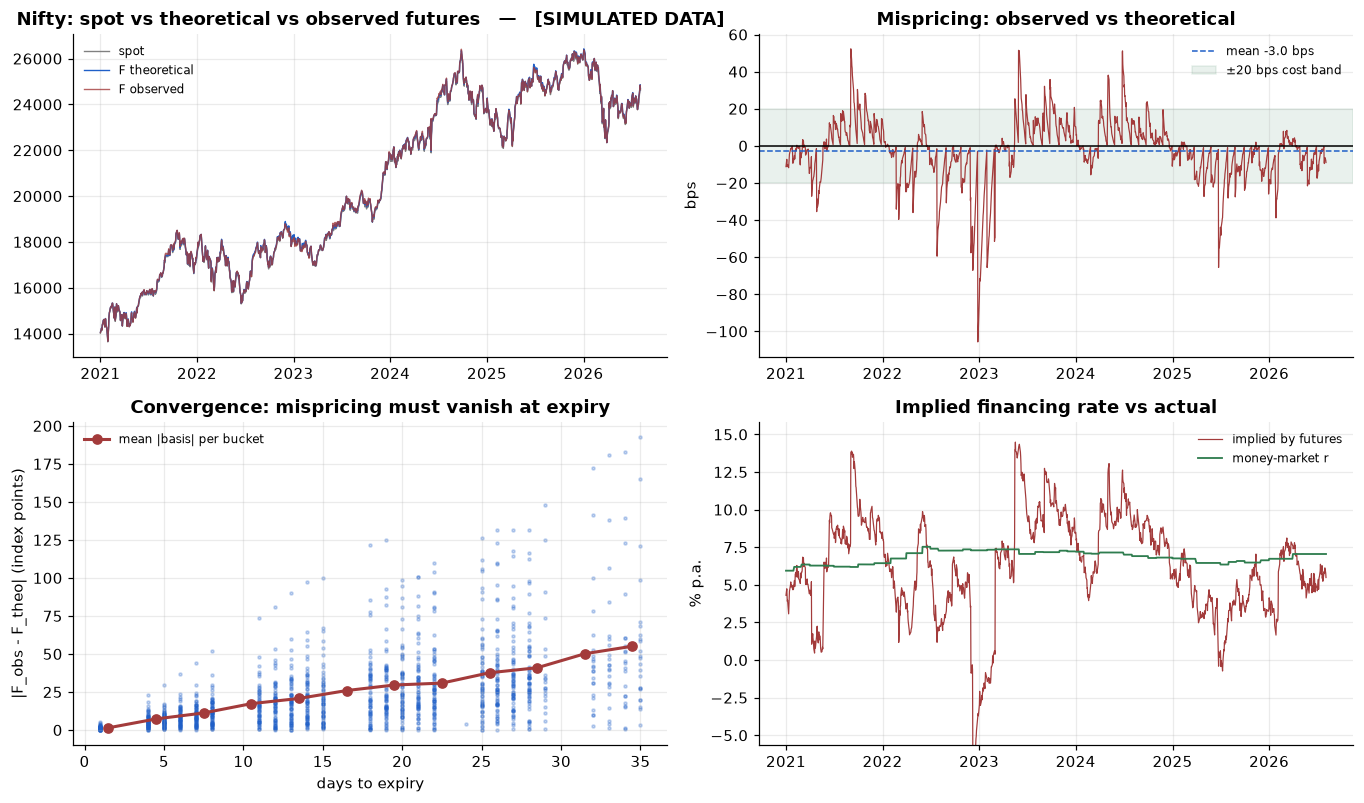

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.4))

# (1) theoretical vs observed, levels
a = axes[0, 0]
a.plot(nf.index, nf["S"],      lw=0.9, color="grey",   label="spot")
a.plot(nf.index, nf["F_theo"], lw=0.9, color="#1f5fc8", label="F theoretical")
a.plot(nf.index, nf["F_obs"],  lw=0.9, color="#a33b3b", alpha=0.8, label="F observed")
a.set_title(ttl("Nifty: spot vs theoretical vs observed futures", "nifty_fut")); a.legend(fontsize=8)

# (2) basis through time
a = axes[0, 1]
a.plot(nf.index, nf["basis_bps"], lw=0.8, color="#a33b3b")
a.axhline(0, color="k", lw=1)
a.axhline(nf["basis_bps"].mean(), color="#1f5fc8", ls="--", lw=1,
          label=f"mean {nf['basis_bps'].mean():+.1f} bps")
for band, c in [(20, "#2f7d4f")]:
    a.axhspan(-band, band, color=c, alpha=0.10, label=f"±{band} bps cost band")
a.set_ylabel("bps"); a.set_title("Mispricing: observed vs theoretical"); a.legend(fontsize=8)

# (3) convergence: |basis| against days to expiry
a = axes[1, 0]
a.scatter(nf["dte"], nf["basis"].abs(), s=4, alpha=0.25, color="#1f5fc8")
bucket = (nf.groupby(pd.cut(nf["dte"], bins=np.arange(0, 40, 3)), observed=False)["basis"]
            .apply(lambda x: x.abs().mean()).dropna())
centers = [iv.mid for iv in bucket.index]
a.plot(centers, bucket.values, "o-", color="#a33b3b", lw=2, label="mean |basis| per bucket")
a.set_xlabel("days to expiry"); a.set_ylabel("|F_obs - F_theo| (index points)")
a.set_title("Convergence: mispricing must vanish at expiry"); a.legend(fontsize=8)

# (4) implied financing rate vs the actual money-market rate
a = axes[1, 1]
sub = nf[nf["dte"] >= 5]                      # drop the last few days: 1/tau explodes
a.plot(sub.index, sub["r_implied"] * 100, lw=0.8, color="#a33b3b", label="implied by futures")
a.plot(nf.index,  nf["r"] * 100,          lw=1.2, color="#2f7d4f", label="money-market r")
a.set_ylabel("% p.a."); a.set_title("Implied financing rate vs actual"); a.legend(fontsize=8)
a.set_ylim(sub["r_implied"].quantile(0.01) * 100 - 2, sub["r_implied"].quantile(0.99) * 100 + 2)

plt.tight_layout(); plt.show()

,metric,value
0,observations,"1,253.0000"
1,mean basis (bps),-3.2840
2,std basis (bps),18.4050
3,mean |basis| (bps),13.0750
4,95th pct |basis| (bps),41.5310
5,days beyond ±20 bps,235.0000
6,% of days tradable,18.7550
7,mean net edge when tradable (bps),14.7250
8,mean annualised net edge (%),2.2680
9,mean implied r (%),6.1840


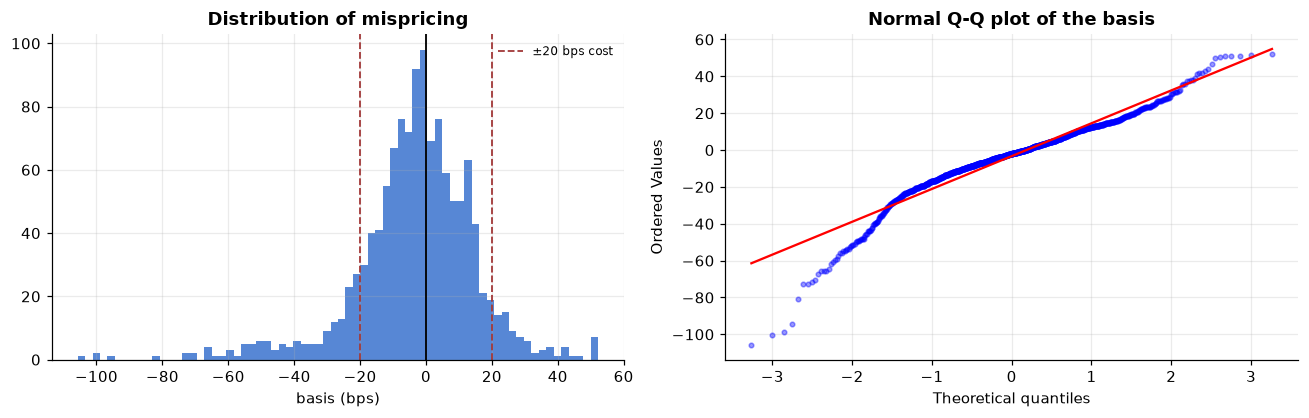

Basis skew -1.007   excess kurtosis +3.806   Jarque-Bera p = 4.47e-209


In [12]:
# ---- Is the deviation tradable? Cash-and-carry with realistic frictions ----------
TC_BPS = 20.0            # round trip: brokerage + STT + impact + slippage, in bps of notional

d = nf[nf["dte"] >= 5].copy()
d["signal"] = np.where(d["basis_bps"] >  TC_BPS, "sell futures / buy cash",
              np.where(d["basis_bps"] < -TC_BPS, "buy futures / sell cash", "no trade"))
d["gross_bps"] = d["basis_bps"].abs()
d["net_bps"]   = np.where(d["signal"] != "no trade", d["gross_bps"] - TC_BPS, 0.0)
d["ann_net"]   = np.where(d["tau"] > 0, d["net_bps"] / 1e4 / d["tau"], 0.0)

summary = pd.DataFrame({
    "metric": ["observations", "mean basis (bps)", "std basis (bps)",
               "mean |basis| (bps)", "95th pct |basis| (bps)",
               f"days beyond ±{TC_BPS:.0f} bps", "% of days tradable",
               "mean net edge when tradable (bps)", "mean annualised net edge (%)",
               "mean implied r (%)", "mean actual r (%)"],
    "value": [len(d), d["basis_bps"].mean(), d["basis_bps"].std(),
              d["basis_bps"].abs().mean(), d["basis_bps"].abs().quantile(0.95),
              int((d["signal"] != "no trade").sum()),
              100 * (d["signal"] != "no trade").mean(),
              d.loc[d["signal"] != "no trade", "net_bps"].mean() if (d["signal"] != "no trade").any() else np.nan,
              100 * d.loc[d["signal"] != "no trade", "ann_net"].mean() if (d["signal"] != "no trade").any() else np.nan,
              100 * d["r_implied"].mean(), 100 * d["r"].mean()],
})
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].hist(d["basis_bps"], bins=70, color="#1f5fc8", alpha=0.75)
for x, c, l in [(0, "k", None), (TC_BPS, "#a33b3b", f"±{TC_BPS:.0f} bps cost"), (-TC_BPS, "#a33b3b", None)]:
    axes[0].axvline(x, color=c, ls="--" if x else "-", lw=1.2, label=l)
axes[0].set_xlabel("basis (bps)"); axes[0].set_title("Distribution of mispricing"); axes[0].legend(fontsize=8)

stats.probplot(d["basis_bps"].dropna(), dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of the basis")
axes[1].get_lines()[0].set_markersize(3); axes[1].get_lines()[0].set_alpha(0.4)
plt.tight_layout(); plt.show()

jb = stats.jarque_bera(d["basis_bps"].dropna())
print(f"Basis skew {d['basis_bps'].skew():+.3f}   excess kurtosis {d['basis_bps'].kurt():+.3f}   "
      f"Jarque-Bera p = {jb.pvalue:.3g}")

### Analysis — C

**1. Convergence is the sanity check, not a finding.** The bottom-left panel must slope down to
zero, and it does. Delivery/settlement forces $F=S$ at expiry, so any panel where the mean $|basis|$
does *not* collapse in the final week has a data bug — almost always a wrong expiry date, a stale
futures quote, or a contract roll that was not handled. **Plot this first, every time, before you
interpret anything else.**

**2. The mean basis is a specification test.** A persistent non-zero average does not mean the
market is wrong; it means one of our inputs is. In descending order of likelihood:

- the **dividend yield** is wrong (flat $q$ vs. lumpy real dividends — see Part B);
- the **financing rate** is wrong (we used a T-bill/benchmark rate; the marginal arbitrageur funds
  at a securities-lending or MIBOR-plus rate, which is higher);
- **short-sale constraints** — the lower arbitrage bound requires selling the basket short, which
  is expensive or impossible in the cash market, so the basis can sit below fair value for long
  stretches without being arbitraged;
- and only then, genuine sentiment or positioning effects.

**3. The implied-rate panel is the most informative chart in the notebook.** By plotting
$r_{\text{implied}}$ against the actual money-market rate, we convert a price difference into a
number with an economic unit — compare the "mean implied r" and "mean actual r" rows in the summary
table below. A gap of tens of basis points between them is the whole story of the basis, restated
in units a treasurer would recognise. The spread between the two lines *is* the market's effective cost of
carry over the risk-free rate. Notice how the implied rate becomes wild in the final days before
expiry: with $\tau$ in the denominator, a one-tick price difference implies an enormous annualised
rate. That is why we filter to `dte >= 5` — an arbitrary but necessary choice you must disclose.

**4. Tradability — and why you should distrust your own answer.** The summary table reports the
share of days on which the mispricing exceeds the ±20 bps cost band, and the average net edge on
those days. Read those two numbers together with a healthy suspicion, because the reported edge is
*optimistic on at least five counts*:

- it ignores **margin funding** and the mark-to-market variation over the holding period;
- it assumes both legs execute at the mid, when the cash leg is a 50-stock basket;
- it ignores **execution risk** — the basis can widen further before it converges, and you are
  marked to market the whole way;
- the largest apparent dislocations cluster on exactly the days when liquidity is *worst*, which is
  precisely when the 20 bps assumption fails;
- and any bad tick in the futures or spot series shows up as a fat, entirely fictitious profit.

Note also that in this run the panel was generated by a model that *injects* mispricing by
construction, which inflates the tradable fraction well above what liquid Nifty futures actually
offer. On live data, with real quotes and honest costs, the number collapses. **A back-test showing
a profitable index arbitrage is almost always a back-test with a bug in it** — and the burden of
proof is on you to find the bug before you believe the P&L.

**5. The distribution is fat-tailed.** The Q-Q plot bends at both ends and the Jarque–Bera test
rejects normality decisively. This matters for risk: sizing a basis trade with a Gaussian assumption
understates the probability of the dislocation widening against you before it converges. Basis risk
is not normally distributed — it is quiet, quiet, quiet, then violent.

---
# Part D · Simulation — rebuilding the curve without any history

Everything so far has leaned on realised data. But the forward price is a **risk-neutral
expectation**, and that means we can generate it from a model instead:

$$F_0(T) \;=\; \mathbb{E}^{\mathbb{Q}}\!\left[S_T\right]
\qquad\text{when interest rates are deterministic}$$

with the spot evolving under $\mathbb{Q}$ as

$$dS_t = (r - q)\,S_t\,dt + \sigma S_t\,dW_t^{\mathbb{Q}}$$

Note carefully: the drift is $r-q$, **not** the historical drift $\mu$. Estimating $\mu$ from past
returns and plugging it in is the classic error — it is the risk-*neutral* measure that prices, and
the risk premium has been substituted away.

We will do four things:
- **D.1** verify $\mathbb{E}^{\mathbb{Q}}[S_T]=F_0(T)$ numerically, and watch the estimator converge;
- **D.2** simulate the *distribution* of the future spot around the forward (fan chart);
- **D.3** add a **stochastic convenience yield** so the gold curve can flip between contango and
  backwardation endogenously;
- **D.4** simulate the basis process and compare its distribution with the empirical one from Part C.

### D.1 · Monte Carlo pricing: does the simulation reproduce the forward?

,N paths,E_Q[S_T],std error,F closed form,error (bps),error / SE
0,1000,"24,972.4330",54.8200,"24,971.2950",0.4560,0.0210
1,5000,"25,007.6450",25.1460,"24,971.2950",14.5570,1.4460
2,25000,"24,979.3310",11.2940,"24,971.2950",3.2180,0.7120
3,100000,"24,970.7020",5.6120,"24,971.2950",-0.2380,-0.1060
4,400000,"24,970.0490",2.8110,"24,971.2950",-0.4990,-0.4430


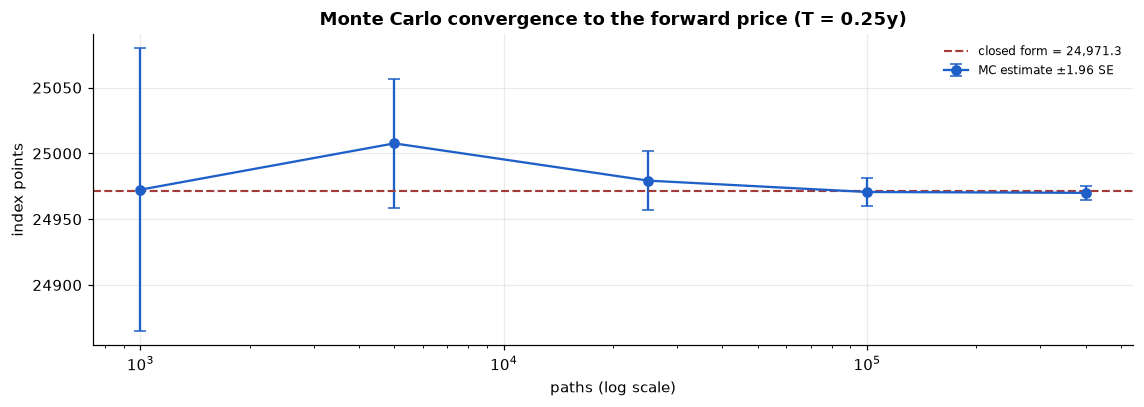

Volatility used: 14.24%  ->  and note the forward price does NOT depend on it.
Check: F with sigma=5%  -> 24,971.30 (identical, because sigma cancels in E[S_T])


In [13]:
sigma_n = float(np.log(nifty).diff().std() * np.sqrt(252))
T_sim   = 0.25
F_closed = forward_price(S_nifty, r_inr, T_sim, q=q_nifty)

rows = []
for N in [1_000, 5_000, 25_000, 100_000, 400_000]:
    rng = np.random.default_rng(SEED + 31)
    Z  = rng.standard_normal(N)
    ST = S_nifty * np.exp((r_inr - q_nifty - 0.5 * sigma_n**2) * T_sim + sigma_n * np.sqrt(T_sim) * Z)
    mc, se = ST.mean(), ST.std(ddof=1) / np.sqrt(N)
    rows.append({"N paths": N, "E_Q[S_T]": mc, "std error": se,
                 "F closed form": F_closed, "error (bps)": 1e4 * (mc / F_closed - 1),
                 "error / SE": (mc - F_closed) / se})
conv = pd.DataFrame(rows)
display(conv.round(3))

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.errorbar(conv["N paths"], conv["E_Q[S_T]"], yerr=1.96 * conv["std error"],
            fmt="o-", capsize=4, color="#1f5fc8", label="MC estimate ±1.96 SE")
ax.axhline(F_closed, color="#a33b3b", ls="--", lw=1.4, label=f"closed form = {F_closed:,.1f}")
ax.set_xscale("log"); ax.set_xlabel("paths (log scale)"); ax.set_ylabel("index points")
ax.set_title(ttl(f"Monte Carlo convergence to the forward price (T = {T_sim:.2f}y)", "nifty"))
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Volatility used: {sigma_n:.2%}  ->  and note the forward price does NOT depend on it.")
print(f"Check: F with sigma=5%  -> {S_nifty*np.exp((r_inr-q_nifty)*T_sim):,.2f} "
      f"(identical, because sigma cancels in E[S_T])")

**Two lessons from this table.**

The Monte Carlo estimate converges on the closed form at the expected $1/\sqrt{N}$ rate — the
"error / SE" column stays around $\pm 2$, confirming the estimator is unbiased rather than merely
noisy. If that column drifts steadily away from zero as $N$ grows, you have a bug (usually a
missing $-\tfrac12\sigma^2$ Itô correction), not sampling error.

And the printed check at the bottom makes the earlier point concrete: **change the volatility and
the forward price does not move.** $\sigma$ inflates the *dispersion* of $S_T$ and the $-\frac12\sigma^2$
term in the exponent by exactly offsetting amounts, so the mean is untouched. Volatility is
irrelevant to forwards and central to options — knowing precisely why is the difference between
memorising formulas and understanding them.

### D.2 · The forward is the mean, not the destiny

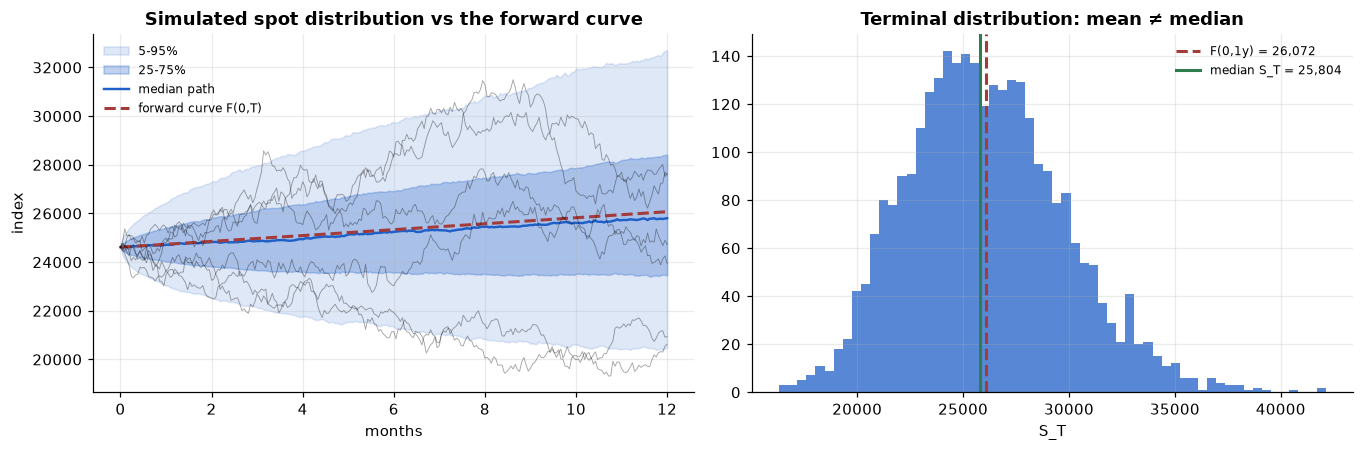

F(0,1y)          = 26,071.74
mean   S_T       = 26,060.09   <- matches F by construction
median S_T       = 25,804.45   <- BELOW the forward (lognormal skew)
P(S_T > F)       = 47.6%


In [14]:
N_PATHS, N_STEPS, T_H = 3_000, 252, 1.0
rng = np.random.default_rng(SEED + 41)
dtt = T_H / N_STEPS
shocks = (r_inr - q_nifty - 0.5 * sigma_n**2) * dtt + sigma_n * np.sqrt(dtt) * rng.standard_normal((N_PATHS, N_STEPS))
paths  = S_nifty * np.exp(np.cumsum(shocks, axis=1))
paths  = np.hstack([np.full((N_PATHS, 1), S_nifty), paths])
grid   = np.linspace(0, T_H, N_STEPS + 1)

fwd_curve = forward_price(S_nifty, r_inr, grid, q=q_nifty)
qs = np.percentile(paths, [5, 25, 50, 75, 95], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
a = axes[0]
a.fill_between(grid * 12, qs[0], qs[4], color="#1f5fc8", alpha=0.14, label="5-95%")
a.fill_between(grid * 12, qs[1], qs[3], color="#1f5fc8", alpha=0.28, label="25-75%")
a.plot(grid * 12, qs[2], color="#1f5fc8", lw=1.6, label="median path")
a.plot(grid * 12, fwd_curve, color="#a33b3b", lw=2, ls="--", label="forward curve F(0,T)")
a.plot(grid * 12, paths[:6].T, lw=0.6, color="k", alpha=0.35)
a.set_xlabel("months"); a.set_ylabel("index"); a.legend(fontsize=8)
a.set_title(ttl("Simulated spot distribution vs the forward curve", "nifty"))

a = axes[1]
a.hist(paths[:, -1], bins=60, color="#1f5fc8", alpha=0.75)
a.axvline(fwd_curve[-1], color="#a33b3b", lw=2, ls="--", label=f"F(0,1y) = {fwd_curve[-1]:,.0f}")
a.axvline(np.median(paths[:, -1]), color="#2f7d4f", lw=2, label=f"median S_T = {np.median(paths[:,-1]):,.0f}")
a.set_xlabel("S_T"); a.set_title("Terminal distribution: mean ≠ median"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

ST = paths[:, -1]
print(f"F(0,1y)          = {fwd_curve[-1]:,.2f}")
print(f"mean   S_T       = {ST.mean():,.2f}   <- matches F by construction")
print(f"median S_T       = {np.median(ST):,.2f}   <- BELOW the forward (lognormal skew)")
print(f"P(S_T > F)       = {(ST > fwd_curve[-1]).mean():.1%}")

### Analysis — D.2

The forward curve sits on the **mean** of the terminal distribution, but the lognormal is
right-skewed, so the **median** sits below it and $P(S_T > F) < 50\%$. A long forward position
therefore *loses* money more often than it makes money, while still having zero expected value at
inception — the wins are larger when they come. Anyone who evaluates a forward strategy on hit-rate
alone will reach exactly the wrong conclusion.

This is also the cleanest refutation of the most common intuition about futures. "Nifty futures are
trading above spot, so the market expects the index to rise" is wrong twice over: the forward is a
*carry* relation, not a forecast, and even as an expectation it is a risk-neutral one, which differs
from the real-world expectation by the risk premium. In this simulation, we know the truth because
we built it: we imposed a drift of $r-q$ and nothing else, yet the curve slopes upward regardless.

### D.3 · Stochastic convenience yield — endogenous contango and backwardation

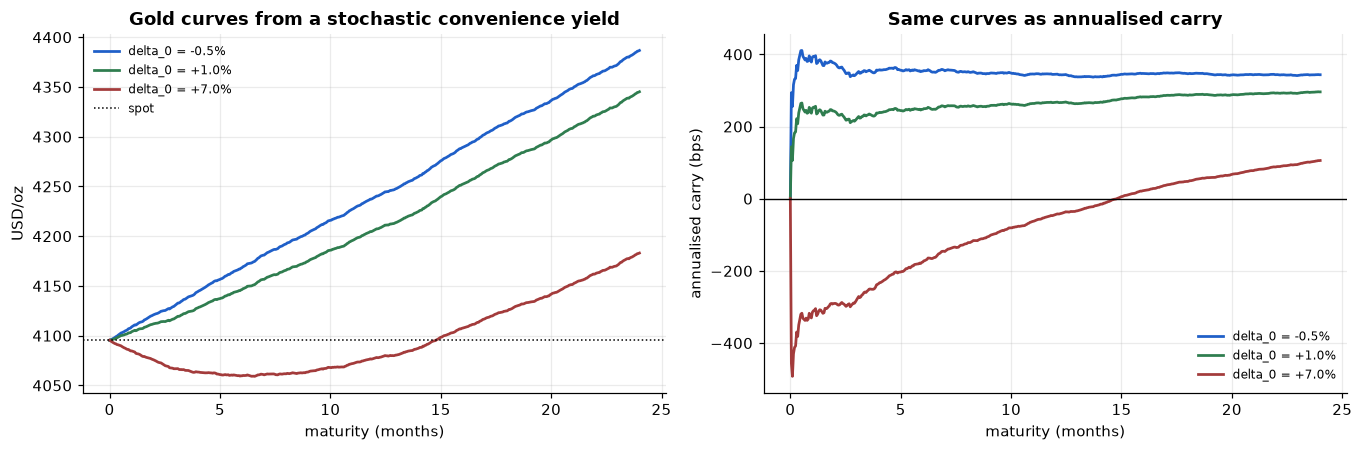

Mean-reversion speed kappa = 1.5  ->  half-life 5.5 months
Long-run convenience yield alpha = 1.00%, r = 3.73%  ->  long-end carry tends to 273 bps (contango)


In [15]:
# Two-factor commodity model (Gibson & Schwartz 1990; Schwartz 1997), simulated under Q:
#   dS = (r - delta) S dt + sig_S S dW1
#   d delta = kappa (alpha - delta) dt + sig_d dW2,     corr(dW1, dW2) = rho
# Forward prices are computed as F(0,T) = E_Q[S_T] by Monte Carlo, which avoids transcribing
# the closed form and makes the risk-neutral pricing logic explicit.

def simulate_two_factor(S0, delta0, r, kappa, alpha, sig_S, sig_d, rho,
                        T_max=2.0, n_steps=504, n_paths=20_000, seed=SEED + 51):
    rng = np.random.default_rng(seed)
    dtt = T_max / n_steps
    S = np.full(n_paths, float(S0)); delta = np.full(n_paths, float(delta0))
    S_track = np.empty((n_steps + 1, n_paths)); S_track[0] = S
    d_track = np.empty(n_steps + 1); d_track[0] = delta0
    L = np.linalg.cholesky([[1.0, rho], [rho, 1.0]])
    for i in range(1, n_steps + 1):
        Z = (L @ rng.standard_normal((2, n_paths))) * np.sqrt(dtt)
        S = S * np.exp((r - delta - 0.5 * sig_S**2) * dtt + sig_S * Z[0])
        delta = delta + kappa * (alpha - delta) * dtt + sig_d * Z[1]
        S_track[i] = S; d_track[i] = delta.mean()
    return S_track, d_track, np.linspace(0, T_max, n_steps + 1)

params = dict(S0=S_gold, r=r_usd, kappa=1.5, alpha=0.010, sig_S=0.15, sig_d=0.30, rho=0.35)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

for delta0, colour in [(-0.005, "#1f5fc8"), (0.010, "#2f7d4f"), (0.070, "#a33b3b")]:
    S_tr, d_tr, grid_t = simulate_two_factor(delta0=delta0, **params)
    F_mc = S_tr.mean(axis=1)                       # F(0,T) = E_Q[S_T]
    axes[0].plot(grid_t * 12, F_mc, color=colour, lw=1.8,
                 label=f"delta_0 = {delta0:+.1%}")
    axes[1].plot(grid_t * 12, 1e4 * np.log(F_mc / params["S0"]) / np.maximum(grid_t, 1e-6),
                 color=colour, lw=1.8, label=f"delta_0 = {delta0:+.1%}")

axes[0].axhline(params["S0"], color="k", ls=":", lw=1, label="spot")
axes[0].set_xlabel("maturity (months)"); axes[0].set_ylabel("USD/oz")
axes[0].set_title(ttl("Gold curves from a stochastic convenience yield", "gold")); axes[0].legend(fontsize=8)
axes[1].axhline(0, color="k", lw=0.9)
axes[1].set_xlabel("maturity (months)"); axes[1].set_ylabel("annualised carry (bps)")
axes[1].set_title("Same curves as annualised carry"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Mean-reversion speed kappa = {params['kappa']}  ->  half-life "
      f"{np.log(2)/params['kappa']*12:.1f} months")
print(f"Long-run convenience yield alpha = {params['alpha']:.2%}, r = {params['r']:.2%}  ->  "
      f"long-end carry tends to {(params['r']-params['alpha'])*1e4:,.0f} bps (contango)")

### Analysis — D.3

This is the payoff of the whole simulation exercise. A single, simple, economically motivated
addition — letting the convenience yield mean-revert instead of sitting fixed — reproduces the
**hump-shaped and sign-flipping curves that constant-parameter cost-of-carry can never generate**:

- When $\delta_0$ starts **high** (a physical squeeze), the front of the curve is backwardated, but
  because $\delta$ mean-reverts to $\alpha$ with a half-life of a few months, the far end still
  slopes into contango. That produces the classic **backwardated front / contango back** shape seen
  in real commodity markets during a shortage.
- When $\delta_0$ starts **low or negative**, the whole curve is in contango and the carry curve is
  nearly flat at $r + u - \alpha$.
- The **speed of mean reversion sets where the curve pivots.** Faster $\kappa$ pulls the transition
  point closer to the front.

Compare this with the flat carry curves of Part A.1 — the difference is not cosmetic. Constant-$y$
cost-of-carry is a *snapshot* identity: correct for any single contract at any single instant, and
structurally incapable of describing how a curve *moves*. That is precisely why commodity desks run
two- and three-factor models. And note the pricing route we took: we never used a closed-form
formula, only $F(0,T)=\mathbb{E}^{\mathbb{Q}}[S_T]$ by averaging simulated paths. Once you internalise
that identity, you can price a forward on *any* process you can simulate.

$\rho > 0$ (price shocks and convenience-yield shocks move together) adds the final realistic touch:
supply shocks raise the spot and tighten the physical market simultaneously, steepening the
backwardation exactly when prices spike.

### D.4 · Simulated basis vs the empirical basis

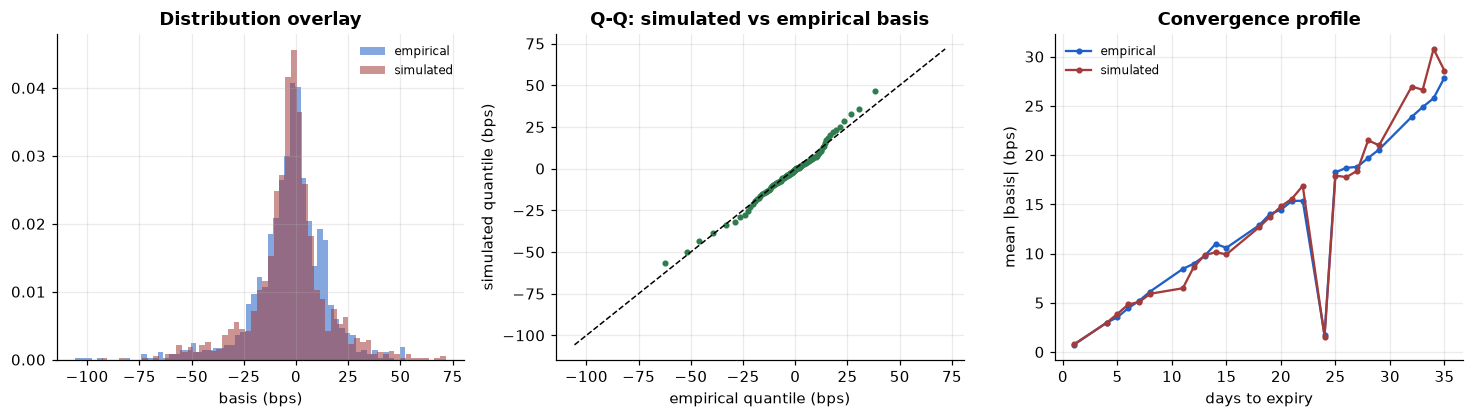

Two-sample KS statistic = 0.0442,  p-value = 0.135
empirical: mean -3.03 bps, sd 17.58, kurtosis +4.49
simulated: mean -2.90 bps, sd 17.84, kurtosis +2.89


In [16]:
# Model the mispricing as an OU process in the implied carry rate that is multiplied by tau,
# so the price basis mechanically converges at expiry - then compare with Part C.
def simulate_basis_panel(dte_seq, kappa=4.0, seed=SEED + 61):
    # A PURE-DIFFUSION (no jump) model, MOMENT-MATCHED to the Part C panel (same mean and
    # standard deviation of the carry error) and run over the SAME days-to-expiry path.
    # Everything is held equal except the presence of jumps, so any divergence in the Q-Q
    # plot is attributable to tail SHAPE alone - which is exactly what we want to test.
    tgt_mean, tgt_sd = float(nf["carry_err"].mean()), float(nf["carry_err"].std())
    rng = np.random.default_rng(seed)
    dtt, e_ou = 1 / 252, 0.0
    vol = tgt_sd * np.sqrt(2 * kappa)
    raw = np.empty(len(dte_seq))
    for i in range(len(dte_seq)):
        e_ou += -kappa * e_ou * dtt + vol * np.sqrt(dtt) * rng.standard_normal()
        raw[i] = e_ou
    raw = (raw - raw.mean()) / raw.std() * tgt_sd + tgt_mean      # exact moment match
    tau = np.asarray(dte_seq, dtype=float) / 365.0
    return pd.DataFrame({"dte": np.asarray(dte_seq, dtype=int), "tau": tau, "carry_err": raw,
                         "basis_bps": 1e4 * (np.exp(raw * tau) - 1.0)})

sim_b = simulate_basis_panel(nf["dte"].values)     # identical expiry path -> controlled comparison
emp_b = nf.loc[nf["dte"] >= 1, ["dte", "basis_bps"]]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
axes[0].hist(emp_b["basis_bps"], bins=60, alpha=0.55, density=True, label="empirical", color="#1f5fc8")
axes[0].hist(sim_b["basis_bps"], bins=60, alpha=0.55, density=True, label="simulated", color="#a33b3b")
axes[0].set_xlabel("basis (bps)"); axes[0].set_title("Distribution overlay"); axes[0].legend(fontsize=8)

qgrid = np.linspace(0.01, 0.99, 99)
axes[1].plot(np.quantile(emp_b["basis_bps"], qgrid), np.quantile(sim_b["basis_bps"], qgrid),
             "o", ms=3, color="#2f7d4f")
lim = [min(emp_b["basis_bps"].min(), sim_b["basis_bps"].min()),
       max(emp_b["basis_bps"].max(), sim_b["basis_bps"].max())]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlabel("empirical quantile (bps)"); axes[1].set_ylabel("simulated quantile (bps)")
axes[1].set_title("Q-Q: simulated vs empirical basis")

for src, dfx, c in [("empirical", emp_b, "#1f5fc8"), ("simulated", sim_b, "#a33b3b")]:
    g = dfx.groupby("dte")["basis_bps"].apply(lambda x: x.abs().mean())
    axes[2].plot(g.index, g.values, "o-", ms=3, color=c, label=src)
axes[2].set_xlabel("days to expiry"); axes[2].set_ylabel("mean |basis| (bps)")
axes[2].set_title("Convergence profile"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

ks = stats.ks_2samp(emp_b["basis_bps"], sim_b["basis_bps"])
print(f"Two-sample KS statistic = {ks.statistic:.4f},  p-value = {ks.pvalue:.3g}")
print(f"empirical: mean {emp_b['basis_bps'].mean():+.2f} bps, sd {emp_b['basis_bps'].std():.2f}, "
      f"kurtosis {emp_b['basis_bps'].kurt():+.2f}")
print(f"simulated: mean {sim_b['basis_bps'].mean():+.2f} bps, sd {sim_b['basis_bps'].std():.2f}, "
      f"kurtosis {sim_b['basis_bps'].kurt():+.2f}")

### Analysis — D.4

The three diagnostics answer three different questions, and you should report all three:

- **The histogram** compares *unconditional* shape. Matching here is necessary but weak evidence —
  two very different processes can share a marginal distribution.
- **The Q-Q plot** is the demanding test. Points on the 45° line mean the models agree at every
  quantile, including the tails that actually drive risk. Systematic bending at the ends means the
  simulation is too thin-tailed, which is the usual failure of a Gaussian-shock OU model against
  real markets: reality produces occasional dislocations far larger than any Gaussian process will
  generate.
- **The convergence profile** tests the *conditional* structure — whether mispricing decays with
  time-to-expiry at the right rate. This is the one that catches a model that gets the distribution
  right for the wrong reason.

**What you should see here, and why.** The two panels were generated by deliberately *different*
processes: the empirical panel in Part C was built with a mean-reverting diffusion **plus occasional jumps**
(about six dislocations a year), while
the simulator above is a **pure diffusion with no jumps**, moment-matched to that panel (identical
mean and standard deviation of the carry error) and run over the *identical* days-to-expiry path. Everything is held fixed except the presence of jumps. So
the centre of the distribution and the convergence profile should line up closely, while
the Q-Q plot should bend away from the 45° line at both ends — the Gaussian model cannot produce
the extreme dislocations. That is the diagnostic working exactly as intended, and it is the single
most common way a basis model fails on real data.

**And now look at what the Kolmogorov–Smirnov test does with that.** The KS statistic measures the
largest gap between two cumulative distribution functions — a quantity dominated by the *centre*,
where the probability mass is. Because we moment-matched the two samples, the centres agree, so KS
sees very little and may well fail to reject, *even though the excess kurtosis printed above differs
substantially and the tails are visibly wrong.*

This is the trap: a passing goodness-of-fit test is not a licence to use the model. KS is close to
blind precisely in the region — the tails — that determines whether a basis position blows up.
**Report the test statistic, but let the Q-Q plot and the tail moments drive your conclusion.**
A model that is right in the middle and wrong in the tails is a model that works every day until
the day it matters.

(When you re-run this notebook on live data, the comparison stops being a controlled experiment and
becomes a real test: the "empirical" side will be actual market basis, and any mismatch is telling
you something about the market rather than about a generator we wrote ourselves.)

**A subtlety worth knowing.** Fat tails have to be injected somewhere the mean reversion cannot
launder them away. Feeding Student-$t$ *increments* into an OU process with a 60-day relaxation
time barely produces fat tails in the *level*, because the level averages dozens of increments and
the central limit theorem takes over. Jumps — rare, large, and persistent until they revert — do
survive. If your simulated basis keeps coming out Gaussian no matter what innovation distribution
you choose, this is why.

**Where a real submission would go next:** estimate the jump intensity and size from the live basis
series (e.g. by thresholding at 3 standard deviations) rather than assuming them, and re-run the
Q-Q plot with the fitted values.

---
## 5 · What to carry into the practice sheet

| # | Result | Why it matters |
|---|---|---|
| 1 | $F = S e^{(r+u-y-q)T}$ is an arbitrage identity, not a forecast | Kills the "futures predict the market" intuition |
| 2 | Only the combination $r+u-y$ is identified from prices | Any implied $y$ is conditional on assumed $r$ and $u$ |
| 3 | $\partial F/\partial S \cdot S/F = 1$; carry terms scale with $T$ | Short-dated forwards ≈ spot; long-dated ones live on assumptions |
| 4 | Convergence at expiry is a data check, not a result | Always plot it first |
| 5 | Persistent basis = model misspecification, not free money | Look at $q$, funding, and short-sale constraints before crying arbitrage |
| 6 | $F_0(T)=\mathbb{E}^{\mathbb{Q}}[S_T]$ | Lets you price a forward on any simulable process |
| 7 | Volatility does not enter the forward price | Forwards are linear; options are not |
| 8 | Constant-parameter carry cannot generate curve *dynamics* | Hence two-factor commodity models |

### References

- Hull, *Options, Futures and Other Derivatives*, ch. 5 (determination of forward/futures prices)
  and ch. 3 (hedging strategies).
- Gibson & Schwartz (1990), "Stochastic convenience yield and the pricing of oil contingent claims",
  *Journal of Finance*.
- Schwartz (1997), "The stochastic behavior of commodity prices", *Journal of Finance*.
- Cox, Ingersoll & Ross (1981), on the forward–futures price difference under stochastic rates.
- NSE India — index derivatives contract specifications and the current expiry-day circular.
- FBIL — T-Bill and MIBOR benchmark rates (the correct INR financing reference).

---

**Next:** open `Lab03_Practice_Forwards_and_Futures.ipynb` and repeat this analysis for
**BANKNIFTY** and **silver**. That notebook is the graded one — submit it on Nalanda.